# Praktikum 1 - Regresi Linier Sederhana

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** Regresi

### Tujuan Praktikum:
1. Memahami karakteristik dataset relasi e-commerce (`dataset.csv`).
2. Menganalisis korelasi antar variabel menggunakan Heatmap dan Pairplot.
3. Membangun model Regresi Linier Sederhana (*Simple Linear Regression*) menggunakan `statsmodels`.
4. Melakukan analisis residual (error terms) untuk menguji asumsi normalitas dan homoskedastisitas.
5. Mengevaluasi performa model pada data uji menggunakan metrik $R^2$ (*R-squared*).

## Langkah 1 & 2 - Import Library

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import statsmodels.api as sm

## Langkah 3 & 4 - Baca Data dan Pemahaman Data

In [2]:
data_path = r'..\Dataset\dataset.csv'

data = pd.read_csv(data_path)
print('Dimensi data:', data.shape)
data.head()

Dimensi data: (500, 8)


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.8 KB


In [4]:
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Langkah 5 - Visualisasi Data dan Korelasi

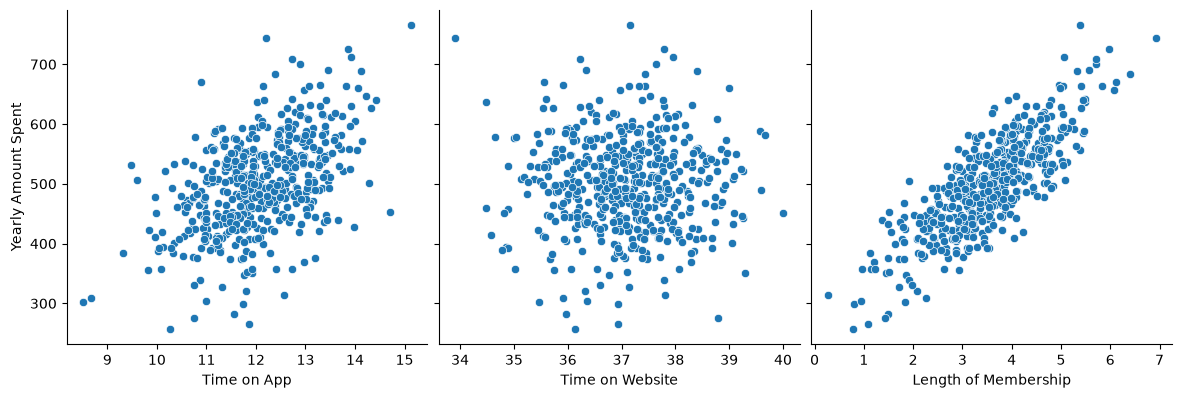

In [5]:
# Visualisasi hubungan variabel numerik terhadap target Yearly Amount Spent
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

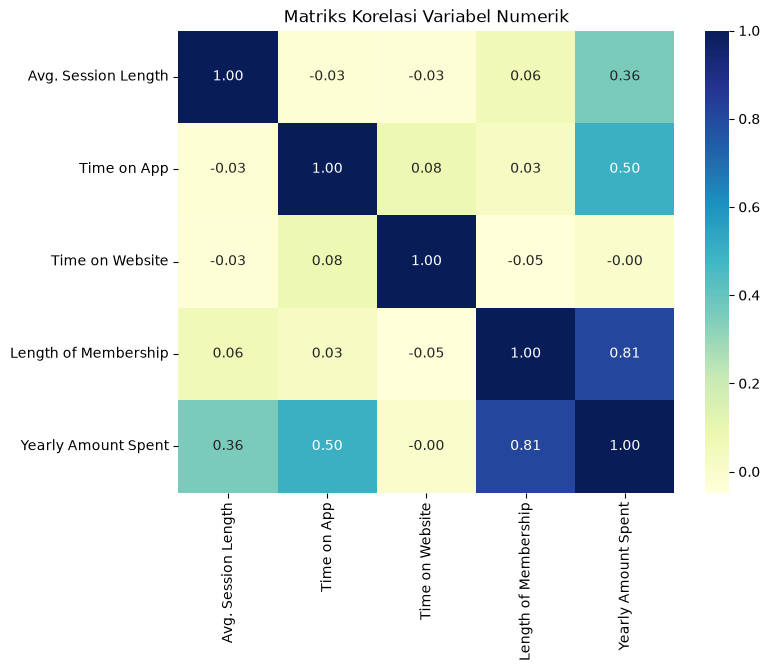

In [6]:
# Visualisasi korelasi antar variabel numerik menggunakan heatmap
numeric_data = data.select_dtypes(include=[np.number])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_data.corr(), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

## Langkah 6 - Pemodelan Regresi Linier Sederhana
Berdasarkan matriks korelasi, variabel `Length of Membership` memiliki korelasi tertinggi (0.81) terhadap target `Yearly Amount Spent`.

In [7]:
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Pembagian data latih (70%) dan data uji (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Menambahkan konstanta intercept
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Thu, 22 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         07:17:13   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

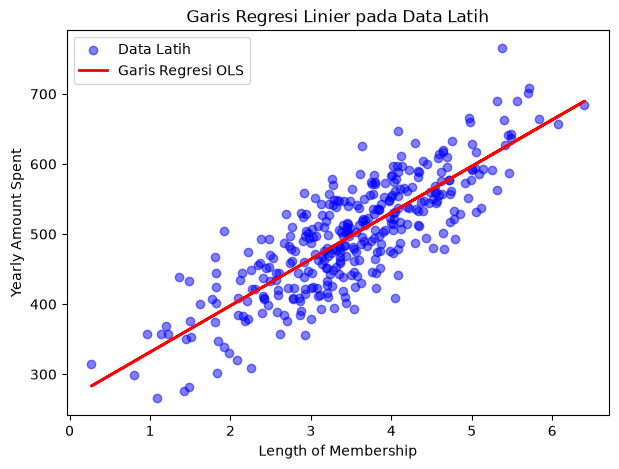

In [8]:
# Visualisasi garis regresi pada data latih
plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Data Latih')
plt.plot(X_train, lr.params.iloc[0] + lr.params.iloc[1] * X_train, 'r', linewidth=2, label='Garis Regresi OLS')
plt.title('Garis Regresi Linier pada Data Latih')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.legend()
plt.show()

## Langkah 7 - Analisis Residual

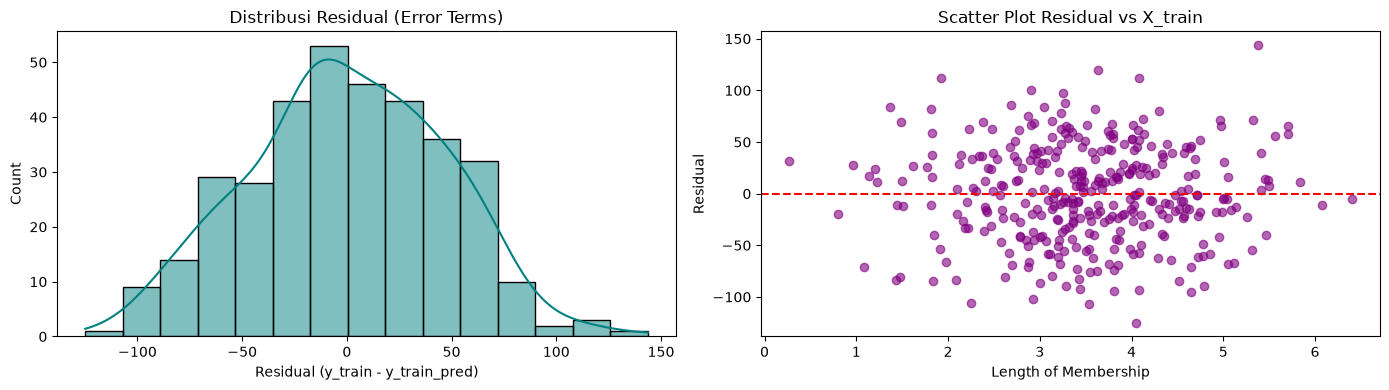

In [9]:
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram residual (cek distribusi normal)
sns.histplot(res, bins=15, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribusi Residual (Error Terms)')
axes[0].set_xlabel('Residual (y_train - y_train_pred)')

# Scatter plot residual (cek homoskedastisitas)
axes[1].scatter(X_train, res, color='purple', alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Scatter Plot Residual vs X_train')
axes[1].set_xlabel('Length of Membership')
axes[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

## Langkah 8 & 9 - Evaluasi pada Data Uji dan Visualisasi

Nilai R-squared pada Data Uji: 0.6119


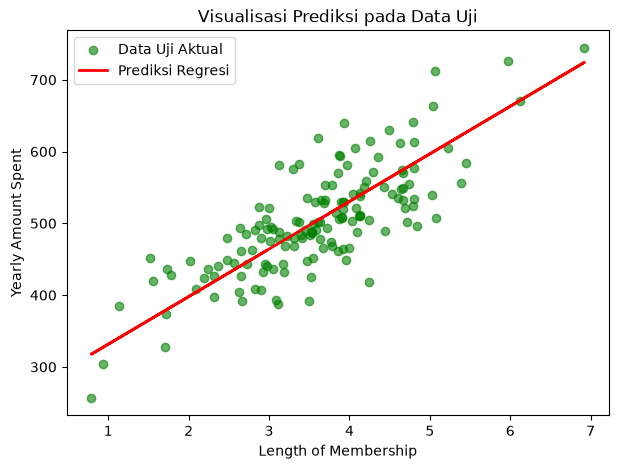

In [10]:
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

r2 = r2_score(y_test, y_test_pred)
print(f'Nilai R-squared pada Data Uji: {r2:.4f}')

# Visualisasi data uji vs garis prediksi
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='green', alpha=0.6, label='Data Uji Aktual')
plt.plot(X_test, y_test_pred, 'r', linewidth=2, label='Prediksi Regresi')
plt.title('Visualisasi Prediksi pada Data Uji')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.legend()
plt.show()